<a href="https://colab.research.google.com/github/Divya-Addagarla/EDA_PROJECT/blob/main/EDA_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/ecommerce_reviews_classification.csv")
df

,review_id,rating_dup,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,R90000,5.0,20105.0,positive,125.0,5.0,Good roduct,No,1033.0
1,R90001,5.0,NaN,positive,80.0,5.0,Terrible quality,No,1080.0
2,R90002,4.0,20356.0,positive,21.0,4.0,NaN,No,1074.0
3,R90003,5.0,20007.0,positive,189.0,5.0,Excellent!,Yes,1092.0
4,R90004,5.0,20261.0,positive,55.0,5.0,Not as expected,Yes,1033.0
...,...,...,...,...,...,...,...,...,...
260,R90056,NaN,20386.0,neutral,14.0,NaN,Terrible quality,Yes,1017.0
261,R90153,4.0,20087.0,positive,197.0,4.0,Terrible quality,No,1064.0
262,R90032,5.0,20481.0,positive,43.0,5.0,Value for money,YES,1088.0
263,R90096,5.0,20173.0,positive,74.0,5.0,Would buy again,No,1080.0


In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          251 non-null    object 
 1   rating_dup         256 non-null    float64
 2   user_id            252 non-null    float64
 3   sentiment          252 non-null    object 
 4   helpful_votes      248 non-null    float64
 5   rating             256 non-null    float64
 6   review_text        245 non-null    object 
 7   verified_purchase  246 non-null    object 
 8   product_id         253 non-null    float64
dtypes: float64(5), object(4)
memory usage: 18.8+ KB


Removing rating_dup column from dataset because it is a duplicate column of "rating"


In [131]:
df.drop('rating_dup', axis=1, inplace=True)

In [132]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          251 non-null    object 
 1   user_id            252 non-null    float64
 2   sentiment          252 non-null    object 
 3   helpful_votes      248 non-null    float64
 4   rating             256 non-null    float64
 5   review_text        245 non-null    object 
 6   verified_purchase  246 non-null    object 
 7   product_id         253 non-null    float64
dtypes: float64(4), object(4)
memory usage: 16.7+ KB


Finding Unique Values in review_id


In [133]:
df["review_id"].unique()

array(['R90000', 'R90001', 'R90002', 'R90003', 'R90004', 'R90005',
       'R90006', 'R90007', 'R90008', 'R90009', 'R90010', 'R90011',
       'R90012', 'R90013', nan, 'R90015', 'R90016', 'R90017', 'R90018',
       'R90019', 'R90020', 'R90021', 'R90022', 'R90023', 'R90024',
       'R90025', 'R90026', 'R90027', 'R90028', 'R90029', 'R90030',
       'R90031', 'R90032', 'R90033', 'R90034', 'R90035', 'R90036',
       'R90037', 'R90038', 'R90039', 'R90040', 'R90041', 'R90042',
       'R90043', 'R90044', 'R90045', 'R90046', 'R90047', 'R90048',
       'R90049', 'R90050', 'R90051', 'R90052', 'R90053', 'R90054',
       'R90055', 'R90056', 'R90057', 'R90058', 'R90059', 'R90061',
       'R90062', 'R90063', 'R90064', 'R90065', 'R90066', 'R90067',
       'R90068', 'R90069', 'R90070', 'R90071', 'R90072', 'R90073',
       'R90074', 'R90075', 'R90076', 'R90077', 'R90078', 'R90079',
       'R90080', 'R90081', 'R90082', 'R90083', 'R90084', 'R90085',
       'R90086', 'R90087', 'R90088', 'R90089', 'R90090', 

Finding Unique Values in user_id


In [134]:
df["user_id"].unique()

array([20105.,    nan, 20356., 20007., 20261., 20342., 20436., 20079.,
       20176., 20391., 20063., 20387., 20287., 20308., 20112., 20450.,
       20318., 20369., 20207., 20443., 20225., 20332., 20416., 20277.,
       20382., 20286., 20279., 20002., 20032., 20477., 20409., 20481.,
       20306., 20213., 20029., 20418., 20024., 20027., 20096., 20086.,
       20025., 20119., 20200., 20352., 20014., 20304., 20253., 20110.,
       20438., 20340., 20127., 20185., 20386., 20392., 20499., 20013.,
       20229., 20090., 20403., 20003., 20151., 20218., 20075., 20283.,
       20354., 20215., 20158., 20250., 20066., 20221., 20191., 20372.,
       20016., 20389., 20494., 20106., 20465., 20226., 20474., 20080.,
       20266., 20165., 20233., 20161., 20174., 20159., 20362., 20375.,
       20173., 20237., 20162., 20475., 20405., 20399., 20117., 20231.,
       20004., 20217., 20407., 20235., 20322., 20031., 20406., 20484.,
       20118., 20189., 20101., 20364., 20485., 20460., 20078., 20321.,
      

Finding Unique Values in product_id


In [135]:
df["product_id"].unique()

array([1033., 1080., 1074., 1092., 1036., 1057., 1059., 1025., 1044.,
       1031.,   nan, 1083., 1070., 1022., 1064., 1038., 1066., 1062.,
       1069., 1094., 1053., 1026., 1078., 1035., 1004., 1050., 1088.,
       1020., 1016., 1072., 1021., 1040., 1058., 1086., 1009., 1054.,
       1003., 1097., 1002., 1049., 1095., 1017., 1006., 1012., 1005.,
       1034., 1052., 1067., 1041., 1071., 1065., 1081., 1011., 1048.,
       1015., 1043., 1093., 1007., 1079., 1037., 1028., 1076., 1001.,
       1087., 1023., 1029., 1060., 1013., 1098., 1061., 1030., 1091.,
       1099., 1000., 1073., 1039., 1090., 1010., 1042., 1055., 1082.,
       1047., 1051., 1008., 1045., 1075., 1084., 1089., 1068., 1077.])

Since 'review_id', 'user_id', 'product_id' contains missing values.we replace all values in these columnns with nan and using arange function to generate new id's

In [136]:
cols = ['review_id', 'user_id', 'product_id']
df[cols] = np.nan
df['review_id'] = np.arange(1, len(df) + 1)
df['user_id'] = np.arange(1, len(df) + 1)
df['product_id'] = np.arange(1, len(df) + 1)

Finding Unique Values in Sentiment


In [137]:
df["sentiment"].unique()

array(['positive', 'neutral', 'negative', nan], dtype=object)

Since sentiment column contains missing values we use mode to replace the missing values

In [138]:
df["sentiment"]=df["sentiment"].fillna(df["sentiment"].mode()[0])
df["sentiment"].unique()

array(['positive', 'neutral', 'negative'], dtype=object)

Finding Unique Values in helpful_values


In [139]:
df["helpful_votes"].unique()

array([125.,  80.,  21., 189.,  55.,  85., 122., 199., 110.,   7.,  61.,
        77., 151.,  14., 155., 149.,  30.,  86.,  68., 108., 166.,  nan,
        39., 182.,  70.,  63.,  43.,  37., 116., 148.,   3., 159.,  54.,
        92., 187.,  58.,  93.,  66.,   4.,  82.,  71., 126.,  26.,  12.,
       133.,  64.,  40., 132.,   0.,  47., 181., 157.,  59.,  65., 173.,
        51.,  34., 120.,  41., 183.,  44., 150.,  28.,  56.,  18., 177.,
       134., 138., 194.,  27.,  88.,  74., 129.,  75., 188., 113., 152.,
        94.,  53., 144., 175.,   1.,  79.,  33., 128.,  99.,  97., 185.,
        49., 100., 118., 139., 114.,  72., 192., 165.,  35., 171., 196.,
       180., 140., 131.,  69., 178., 101., 197.,  10., 109., 186.,  60.,
       167., 154.,  15.,   6., 179., 127.,   5., 119., 193.,  84.,  57.,
        23., 158., 168.,  67., 106.,   9., 164.,  20., 123., 112.,  96.,
       137.,  81., 111., 130., 146.,   8., 176.])

Since helpful_votes column contains missing values we use mode to replace the missing values

In [140]:
df["helpful_votes"]=df["helpful_votes"].fillna(df["helpful_votes"].mode()[0])

As helpful_votes are in floating type we convert them to int by using round and astype

In [141]:
df["helpful_votes"] = df["helpful_votes"].round(0).astype(int)
df["helpful_votes"]

,helpful_votes
0,125
1,80
2,21
3,189
4,55
...,...
260,14
261,197
262,43
263,74


After filling missing values finding Unique Values in helpful_values


In [142]:
df["helpful_votes"].unique()

array([125,  80,  21, 189,  55,  85, 122, 199, 110,   7,  61,  77, 151,
        14, 155, 149,  30,  86,  68, 108, 166,  39, 182,  70,  63,  43,
        37, 116, 148,   3, 159,  54,  92, 187,  58,  93,  66,   4,  82,
        71, 126,  26,  12, 133,  64,  40, 132,   0,  47, 181, 157,  59,
        65, 173,  51,  34, 120,  41, 183,  44, 150,  28,  56,  18, 177,
       134, 138, 194,  27,  88,  74, 129,  75, 188, 113, 152,  94,  53,
       144, 175,   1,  79,  33, 128,  99,  97, 185,  49, 100, 118, 139,
       114,  72, 192, 165,  35, 171, 196, 180, 140, 131,  69, 178, 101,
       197,  10, 109, 186,  60, 167, 154,  15,   6, 179, 127,   5, 119,
       193,  84,  57,  23, 158, 168,  67, 106,   9, 164,  20, 123, 112,
        96, 137,  81, 111, 130, 146,   8, 176])

Finding Unique Values in rating


In [143]:
df["rating"].unique()

array([ 5.,  4.,  3.,  1.,  2., nan])

Since rating column contains missing values we use mode to replace the missing values

In [144]:
df["rating"]=df["rating"].fillna(df["rating"].mode()[0])
df["rating"]

,rating
0,5.0
1,5.0
2,4.0
3,5.0
4,5.0
...,...
260,4.0
261,4.0
262,5.0
263,5.0


After filling missing values finding Unique Values in rating


In [145]:
df["rating"].unique()

array([5., 4., 3., 1., 2.])

finding unique values in reveiw_text

In [146]:
df["review_text"].unique()

array(['Good roduct', 'Terrible quality', nan, 'Excellent!',
       'Not as expected', 'Would buy again', 'Value for money',
       'EXCELLENT!', 'Value fo money', 'Good product', 'Not as expcted',
       'Would uy again', 'Not s expected', 'Good poduct',
       'Value for mone', 'NOT AS EXPECTED', 'TERRIBLE QUALITY',
       'Excelent!', 'Value for mony', 'Ecellent!', 'WOULD BUY AGAIN',
       'Not as expecte', 'Good produc', 'Terrible uality',
       'VALUE FOR MONEY', 'Would buy aain', 'Terible quality',
       'Goodproduct'], dtype=object)

Since review_text contains incorrect values they are replace with their correct values

In [147]:
df['review_text'] = df['review_text'].replace({
    'Good roduct': 'Good product',
    'Good poduct': 'Good product',
    'Good produc': 'Good product',
    'Goodproduct': 'Good product',

    'Excelent!': 'Excellent!',
    'Ecellent!': 'Excellent!',
    'EXCELLENT!': 'Excellent!',

    'Terrible uality': 'Terrible quality',
    'Terible quality': 'Terrible quality',
    'TERRIBLE QUALITY': 'Terrible quality',

    'Not as expcted': 'Not as expected',
    'Not s expected': 'Not as expected',
    'Not as expecte': 'Not as expected',
    'NOT AS EXPECTED': 'Not as expected',

    'Would uy again': 'Would buy again',
    'Would buy aain': 'Would buy again',
    'WOULD BUY AGAIN': 'Would buy again',

    'Value fo money': 'Value for money',
    'Value for mone': 'Value for money',
    'Value for mony': 'Value for money',
    'VALUE FOR MONEY': 'Value for money'
})

Since review_text column contains missing values we use mode to replace the missing values

In [148]:
df['review_text']=df['review_text'].fillna(df['review_text'].mode()[0])
df["review_text"]

,review_text
0,Good product
1,Terrible quality
2,Terrible quality
3,Excellent!
4,Not as expected
...,...
260,Terrible quality
261,Terrible quality
262,Value for money
263,Would buy again


After filling missing values finding Unique Values in review_text


In [149]:
df['review_text'].unique()

array(['Good product', 'Terrible quality', 'Excellent!',
       'Not as expected', 'Would buy again', 'Value for money'],
      dtype=object)

finding unique values in verified_purchase

In [150]:
df["verified_purchase"].unique()

array(['No', 'Yes', nan, 'Ye', 'Ys', 'YES', 'es', 'NO', 'o', 'N'],
      dtype=object)

Since verified purchase contains incorrect values they are replace with their correct values

In [151]:
df['verified_purchase'] = df['verified_purchase'].replace({
    'Ye': 'Yes',
    'Ys': 'Yes',
    'YES': 'Yes',
    'es': 'Yes',
    'NO': 'No',
    'o': 'No',
    'N': 'No'
})

Since verified_purchase column contains missing values we use mode to replace the missing values

In [152]:
df["verified_purchase"]=df["verified_purchase"].fillna(df["verified_purchase"].mode()[0])
df["verified_purchase"]

,verified_purchase
0,No
1,No
2,No
3,Yes
4,Yes
...,...
260,Yes
261,No
262,Yes
263,No


After filling missing values finding Unique Values in verified_purchase


In [153]:
df["verified_purchase"].unique()

array(['No', 'Yes'], dtype=object)

In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          265 non-null    int64  
 1   user_id            265 non-null    int64  
 2   sentiment          265 non-null    object 
 3   helpful_votes      265 non-null    int64  
 4   rating             265 non-null    float64
 5   review_text        265 non-null    object 
 6   verified_purchase  265 non-null    object 
 7   product_id         265 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 16.7+ KB


finding outliers in all the columns

<Axes: xlabel='review_id'>

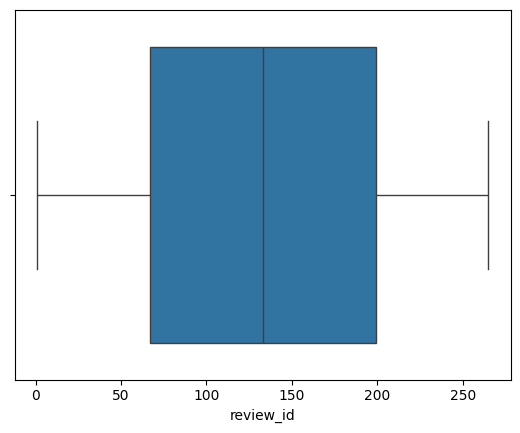

In [155]:
sns.boxplot(data=df,x="review_id")

<Axes: xlabel='user_id'>

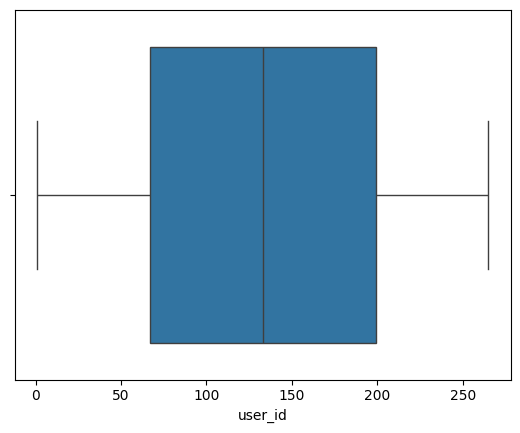

In [156]:
sns.boxplot(data=df,x="user_id")

<Axes: xlabel='sentiment'>

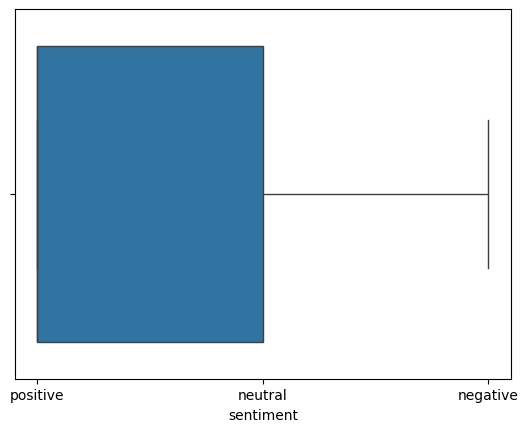

In [157]:
sns.boxplot(data=df, x="sentiment")

<Axes: xlabel='helpful_votes'>

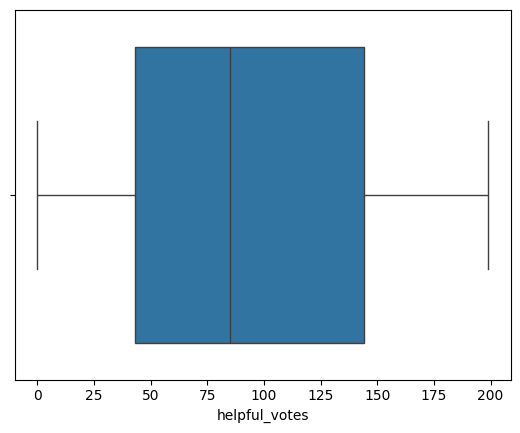

In [158]:
sns.boxplot(data=df, x="helpful_votes")

<Axes: xlabel='rating'>

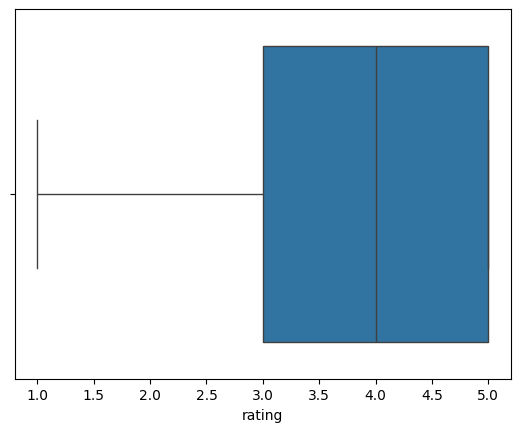

In [159]:
sns.boxplot(data=df, x="rating")

<Axes: xlabel='review_text'>

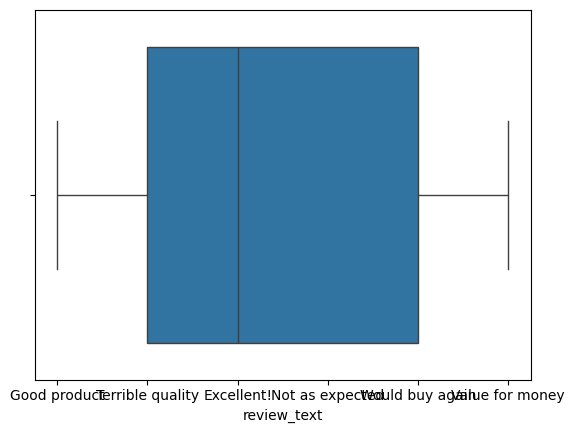

In [160]:
sns.boxplot(data=df, x="review_text")

<Axes: xlabel='verified_purchase'>

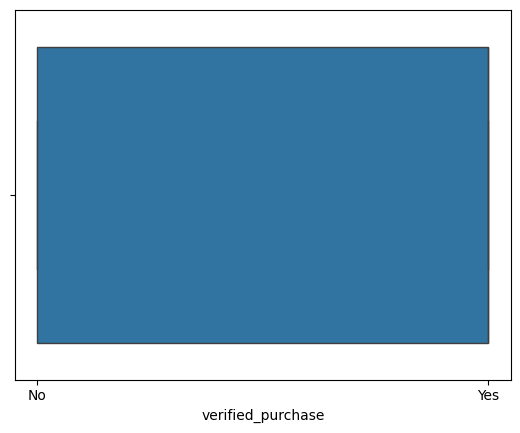

In [161]:
sns.boxplot(data=df,x="verified_purchase")

<Axes: xlabel='product_id'>

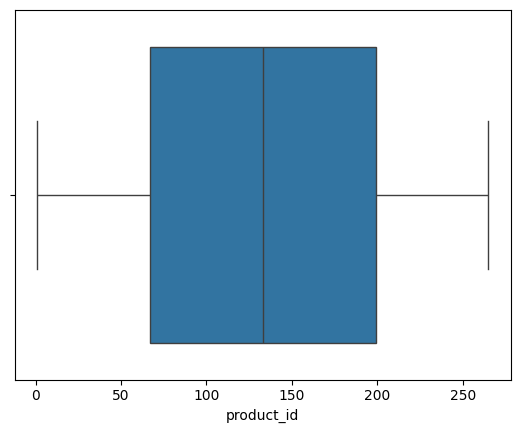

In [162]:
sns.boxplot(data=df,x="product_id")

In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          265 non-null    int64  
 1   user_id            265 non-null    int64  
 2   sentiment          265 non-null    object 
 3   helpful_votes      265 non-null    int64  
 4   rating             265 non-null    float64
 5   review_text        265 non-null    object 
 6   verified_purchase  265 non-null    object 
 7   product_id         265 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 16.7+ KB


In [164]:
out_cols = ['review_id', 'rating', 'helpful_votes', 'user_id', 'product_id']
for col in out_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, ":", len(outliers), "Outliers")

review_id : 0 Outliers
rating : 0 Outliers
helpful_votes : 0 Outliers
user_id : 0 Outliers
product_id : 0 Outliers


save the preprocessed data set

In [165]:
df.to_csv("preprocessed_ecommerce_reviews.csv", index=False)
print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


load the pre processed data set

In [166]:
df1=pd.read_csv("/content/preprocessed_ecommerce_reviews.csv")
df1

,review_id,user_id,sentiment,helpful_votes,rating,review_text,verified_purchase,product_id
0,1,1,positive,125,5.0,Good product,No,1
1,2,2,positive,80,5.0,Terrible quality,No,2
2,3,3,positive,21,4.0,Terrible quality,No,3
3,4,4,positive,189,5.0,Excellent!,Yes,4
4,5,5,positive,55,5.0,Not as expected,Yes,5
...,...,...,...,...,...,...,...,...
260,261,261,neutral,14,4.0,Terrible quality,Yes,261
261,262,262,positive,197,4.0,Terrible quality,No,262
262,263,263,positive,43,5.0,Value for money,Yes,263
263,264,264,positive,74,5.0,Would buy again,No,264


In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          265 non-null    int64  
 1   user_id            265 non-null    int64  
 2   sentiment          265 non-null    object 
 3   helpful_votes      265 non-null    int64  
 4   rating             265 non-null    float64
 5   review_text        265 non-null    object 
 6   verified_purchase  265 non-null    object 
 7   product_id         265 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 16.7+ KB


**UNIVARIATE ANALYSIS**


1.Histogram-Analyzed the distribution of customer ratings using a histogram.

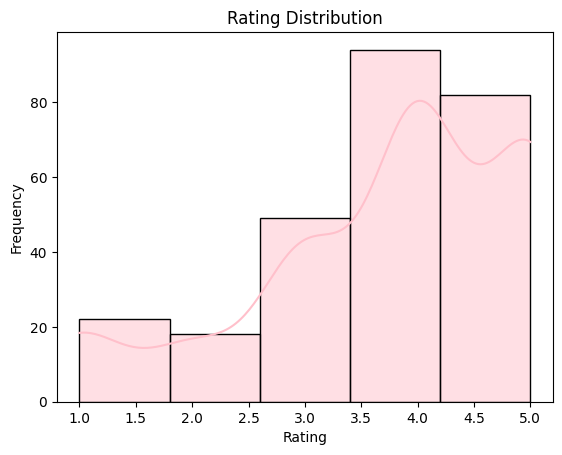

In [191]:
sns.histplot(df['rating'], bins=5, kde=True,color="pink")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

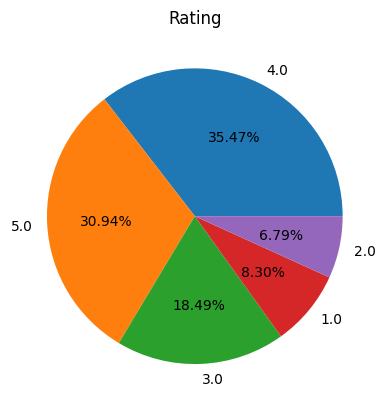

In [169]:
rating_count=df["rating"].value_counts()
plt.pie(rating_count.values,labels=rating_count.index,autopct='%1.2f%%')
plt.title("Rating")
plt.show

3.Count-Plot:Analyzed the number of positive, negative and neutral customer reviews.

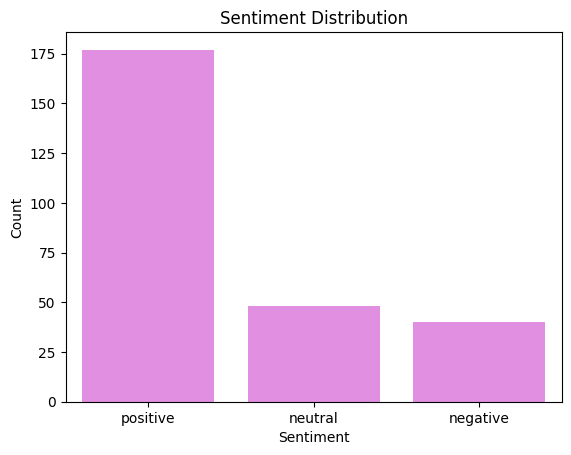

In [175]:
sns.countplot(data=df,x="sentiment",color="violet")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

4.Density-plot:studied the density and shape of the helpful votes distribution.

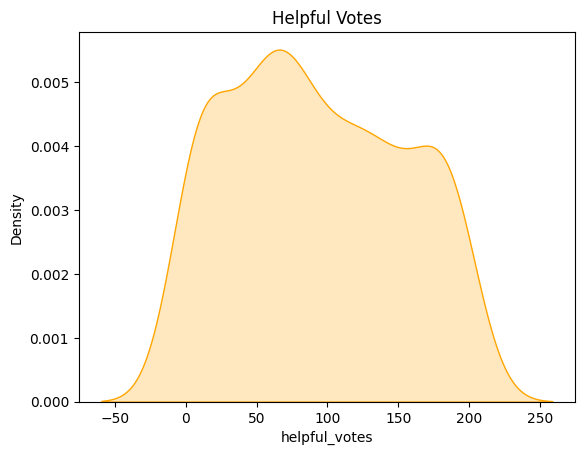

In [176]:
sns.kdeplot(data=df, x='helpful_votes', fill=True,color="orange")
plt.title("Helpful Votes")
plt.show()

5.Violin-plot:Visualized the distribution and density of helpful votes.

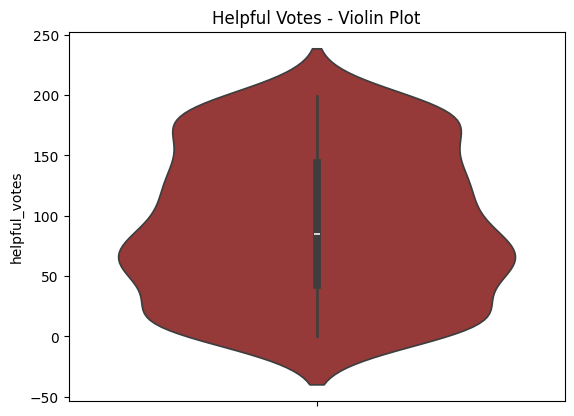

In [177]:
sns.violinplot(y=df['helpful_votes'],color="brown")
plt.title("Helpful Votes - Violin Plot")
plt.show()

**BIVARIATE ANALYSIS**

1.Scatter-plot:Analyzed the relationship between customer ratings and helpful votes

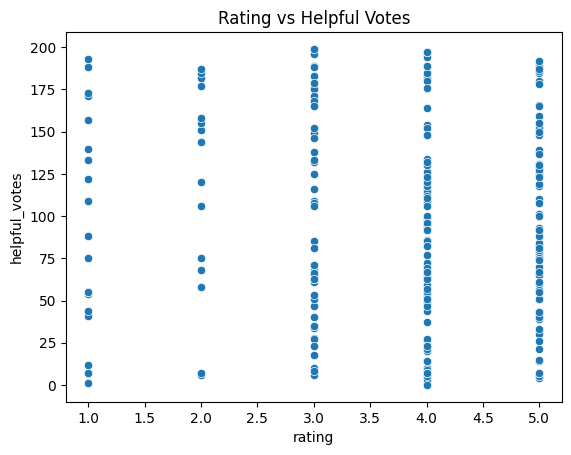

In [173]:
sns.scatterplot(data=df, x='rating', y='helpful_votes')
plt.title("Rating vs Helpful Votes")
plt.show()

2.Stacked-bar-plot:Compared the average customer rating across different sentiment categories.

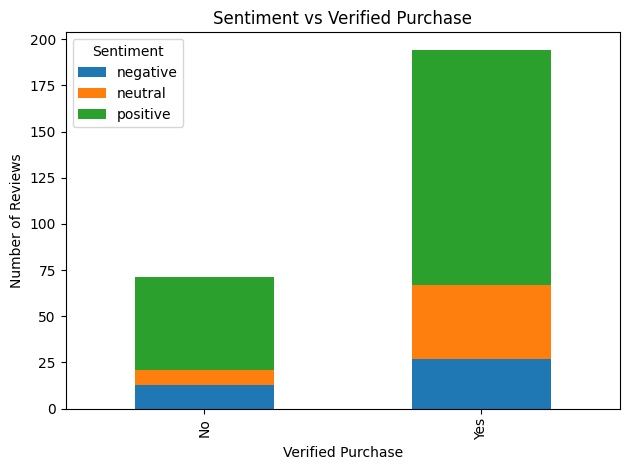

In [194]:
data = pd.crosstab(df['verified_purchase'],df['sentiment'])
data.plot(kind='bar',stacked=True,)
plt.title("Sentiment vs Verified Purchase")
plt.xlabel("Verified Purchase")
plt.ylabel("Number of Reviews")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

3.Grouped Count Plot with Hue:Compared sentiment categories based on verified purchase status.

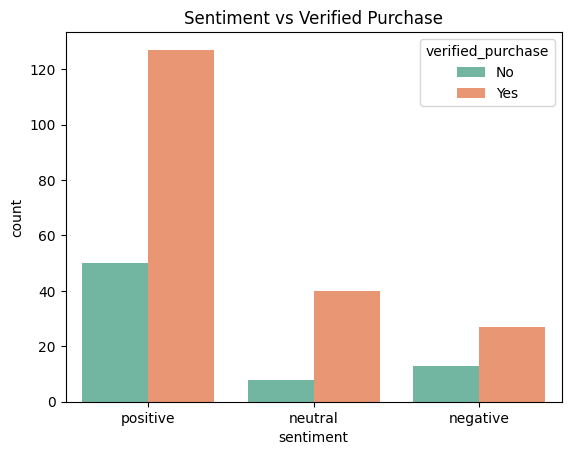

In [187]:
sns.countplot(data=df, x='sentiment',hue='verified_purchase', palette='Set2')
plt.title("Sentiment vs Verified Purchase")
plt.show()

4.Box Plot:Compared the distribution of customer ratings between verified and non-verified purchases.

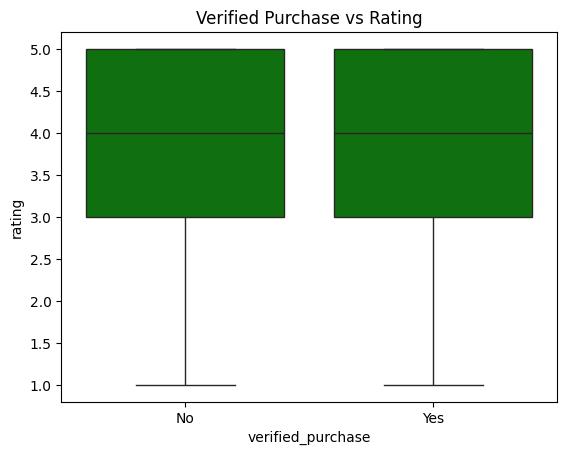

In [184]:
sns.boxplot(data=df, x='verified_purchase', y='rating',color="Green")
plt.title("Verified Purchase vs Rating")
plt.show()

**MUTLIVARIATE ANALYSIS**

1.Pair Plot-Analyzed the relationships between rating, helpful votes and sentiment using a pair plot to understand patterns among multiple variables.

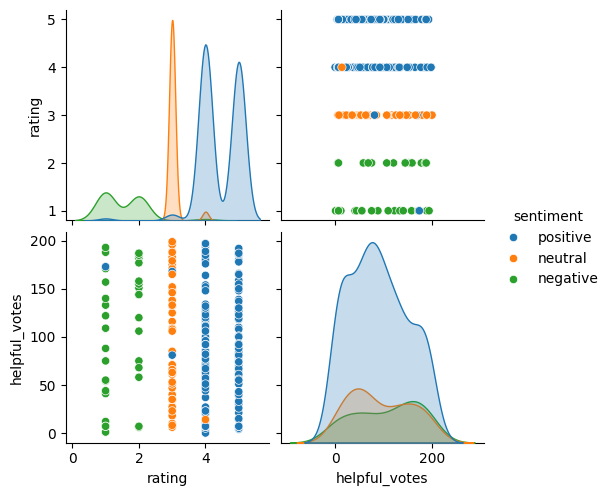

In [182]:
sns.pairplot(data=df, vars=["rating", "helpful_votes"], hue="sentiment")
plt.show()

2.Heatmap-Analyzed the correlations among multiple numerical variables using a correlation matrix and visualized their relationships through a heatmap.

<Axes: >

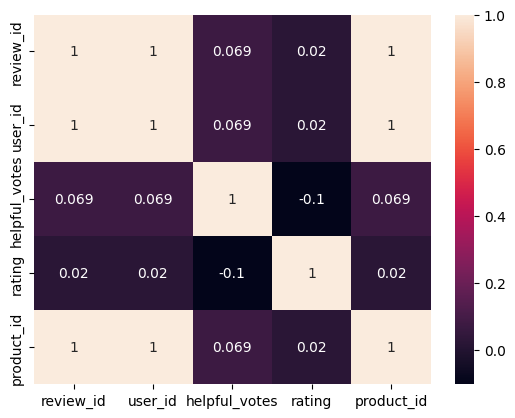

In [183]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

**FINAL ANALYSIS REPORT**

1.The E-commerce Reviews dataset was successfully loaded, explored and preprocessed by handling missing values, removing duplicate records and cleaning inconsistent data.

2.Missing numerical values were handled using median, while categorical values were handled using mode.

3.Outlier detection was performed using the IQR method and also the box plot is used to check the outliers and no outliers were detected in the selected numerical columns.

4.Univariate analysis was performed using five different visualizations to understand individual variable distributions.

5.Bivariate analysis was performed using four different visualizations to identify relationships between two variables.

6.Multivariate analysis was performed using pair plots and correlation heatmaps to study relationships among multiple variables.

7.Overall, the analysis helped understand customer ratings, sentiments, helpful votes, review patterns and verified purchase behaviour.